# Measured coronary spectral OCT: active reconstruction


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`fringes`，shape `(1, 2, 1600, 1024)`，dtype `<u2`：Native detector ADU; axes batch, detector channel, sweep sample, A-line；`background`，shape `(1, 2, 1600)`，dtype `<f4`：Mean independent background B scan in ADU; same detector-channel and sweep order；`chirp`，shape `(1, 800)`，dtype `<f8`：Dimensionless normalized spectral calibration coordinate, native deposited calibration convention；`dispersion`，shape `(1, 1600)`，dtype `<f4`：Dimensionless complex spectral phase correction encoded as first 800 real parts then 800 imaginary parts。未知量为双偏振2048深度×1024A-line复散射场。

获取模型：非线性扫频和色散作用于深度散射的复Fourier干涉，取实部并加独立背景。

如何恢复：src.solvers.reconstruct：background去除、analytic_spectrum、chirp插值/色散校正和depth_transform。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell6调用run_experiments主动重建并三图显示原始条纹/校准、复断层与校准消融；cell8冻结指标。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留1个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。无独立冠脉解剖或散射真值；光程微米尺度/绝对散射系数不可识别。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct the complex depth-resolved backscattering image of a coronary artery from measured polarization-diverse interferometric fringes with nonlinear spectral sampling and dispersion.

This notebook reconstructs the entire native human coronary B scan, then evaluates independently reproduced original measurements. The images are complex digital backscatter, not independent anatomical truth. No saved reconstruction is substituted for fresh computation.


## 2. Data

| Key | Shape | Dtype | Description |
|---|---|---|---|
| fringes | (1, 2, 1600, 1024) | uint16 | Native detector ADU; axes batch, detector channel, sweep sample, A-line |
| background | (1, 2, 1600) | float32 | Mean independent background B scan in ADU; same detector-channel and sweep order |
| chirp | (1, 800) | float64 | Dimensionless normalized spectral calibration coordinate, native deposited calibration convention |
| dispersion | (1, 1600) | float32 | Dimensionless complex spectral phase correction encoded as first 800 real parts then 800 imaginary parts |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Detector sample rate | 180 | MHz | Deposited capture clock |
| Sweep samples per detector | 1600 | sample | Native digitization length |
| A-lines | 1024 | line | Complete recorded lateral scan; no circumferential resampling |
| Detector channels | 2 | channel | Polarization-diverse detection, native channel order |
| Recorded B scans | 1 | B scan | Entire deposited selected acquisition |
| ADC | unsigned 16-bit, little endian | ADU | Original digitizer representation |
| Input voltage range | 2200 | mV | Deposited channel A and B voltage setting |
| Analytic spectral support | first 800 DFT bins | bin | Positive-frequency half of native spectral DFT |
| Carrier | 400 | native DFT bin | Heterodyne frequency offset |
| Spectral zoom | 2 | dimensionless | Oversampled analytic fringe representation |
| Depth bins | 2048 | bin | Full calibrated image depth grid |
| Phase convention | negative-sign forward DFT | dimensionless | Complex quadratures retained |
| Boundaries | finite spectral aperture, zero extension | dimensionless | No spatial circular extension of anatomy |
| Lateral/depth physical pitch | not deposited | unavailable | Coordinates are A-line and depth-bin indices |
| Wavelength and absolute optical power | not deposited | unavailable | Calibrated normalized spectral coordinates define the digital reconstruction |
| Noise variance | not independently calibrated | unavailable | No invented Gaussian/Poisson variance |


## 3. Physics

The acquisition is one complete recorded coronary-artery B scan with two polarization-diverse detector channels. The unknown is a complex spatial depth profile at every A-line and channel. A single-scattering interferometric model is


$$
I_c(n,a)=b_c(n)+2\operatorname{Re}\left[e^{2\pi i q n/N}\int r_c(z,a)e^{2ik(n)z+i\psi(n)}\,dz\right]+\eta_c(n,a).
$$


Here I is the measured detector signal, c indexes detection polarization, n the sweep sample, a the lateral A-line, b the independently measured reference background, r the complex backscatter field, z optical path depth, k the nonlinear optical wavenumber, psi differential dispersion, q the digital heterodyne carrier, N the sweep length, eta detector/model noise, and i the imaginary unit. The public chirp and dispersion arrays describe the calibrated spectral reparameterization and phase correction. Bandwidth and finite sampling limit axial resolution and depth range. The absolute tissue scattering coefficient, path depth in micrometers, and catheter rotation calibration are not deposited, so the output uses the declared digital depth and A-line coordinates.


The physics is depth-dependent interference: each tissue reflector creates a spectral fringe, and nonlinear sweep sampling plus dispersion require independent calibration. The two detector channels measure polarization-diverse scattered fields. See the public README and maintained plans for all coordinate and digital scale conventions.


## 4. Method

### Explicit inverse and scientific comparisons
For each detector channel subtract the independent background in the original integer ADC convention. The positive half of the unnormalized native DFT is padded to length3200, shifted by−400bins, and inverse transformed with scale3200. Calibrated index interpolation and complex dispersion correction produce the uniform spectral fringe. A length800Hann aperture precedes the length2048negative-sign DFT with10^-6scale. Roll+1024and reverse depth. This fixes phase, amplitude, depth orientation and sidelobe convention.

The following three figure groups show actual observed/calibration data, fresh full complex reconstructions, and fresh no-dispersion/rectangular-aperture ablations. The ablations expose calibration and bandwidth sensitivity; no unmeasured anatomy reference or clinical performance claim is inferred.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.visualization import run_experiments,make_figures,relative_error
data=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f: upstream=f['reconstruction'].copy()
start=time.perf_counter()
experiments=run_experiments(data,upstream)
runtime=time.perf_counter()-start
print(json.dumps({'fresh_experiment_runtime_s':runtime,**experiments['metrics']},indent=2))
assert experiments['metrics']['nominal_upstream_relative_l2']<2e-5

{
  "fresh_experiment_runtime_s": 1.272881699998834,
  "nominal_upstream_relative_l2": 0.0,
  "no_dispersion_change": 1.6091532328970248,
  "rectangular_window_change": 0.5833476914477054
}


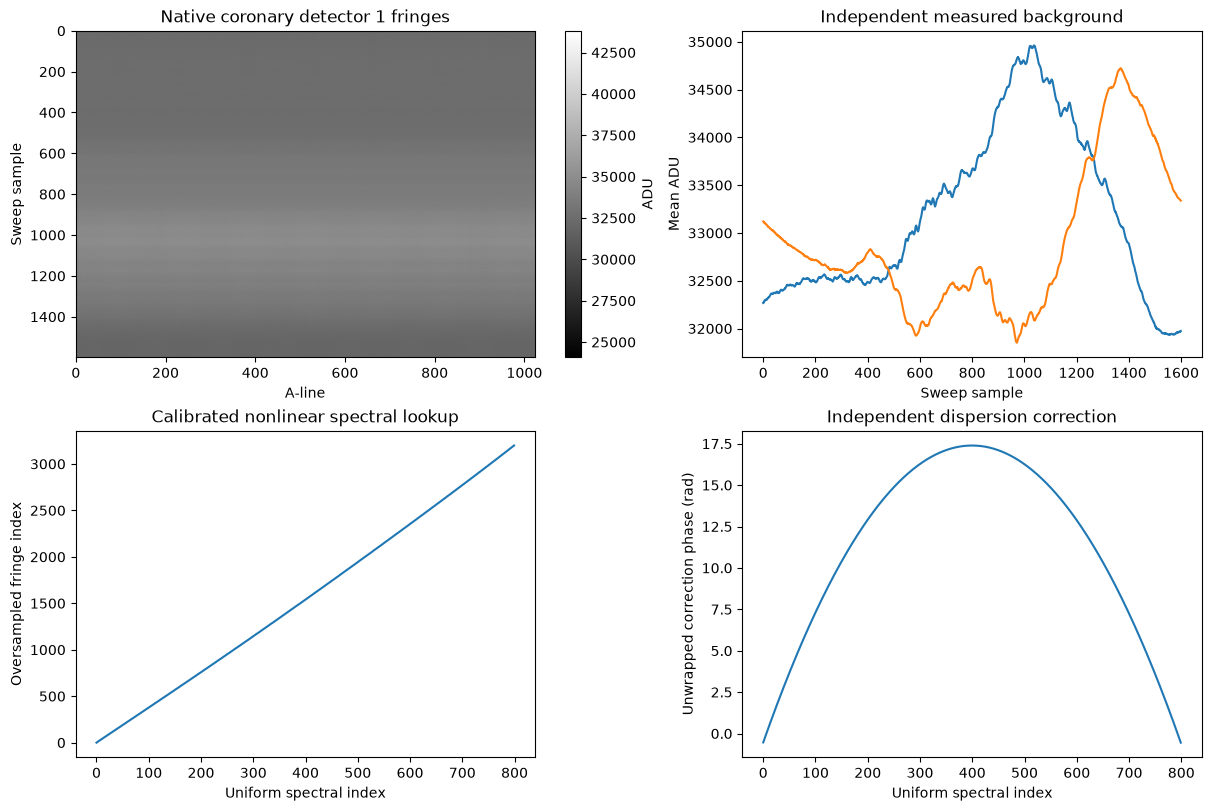

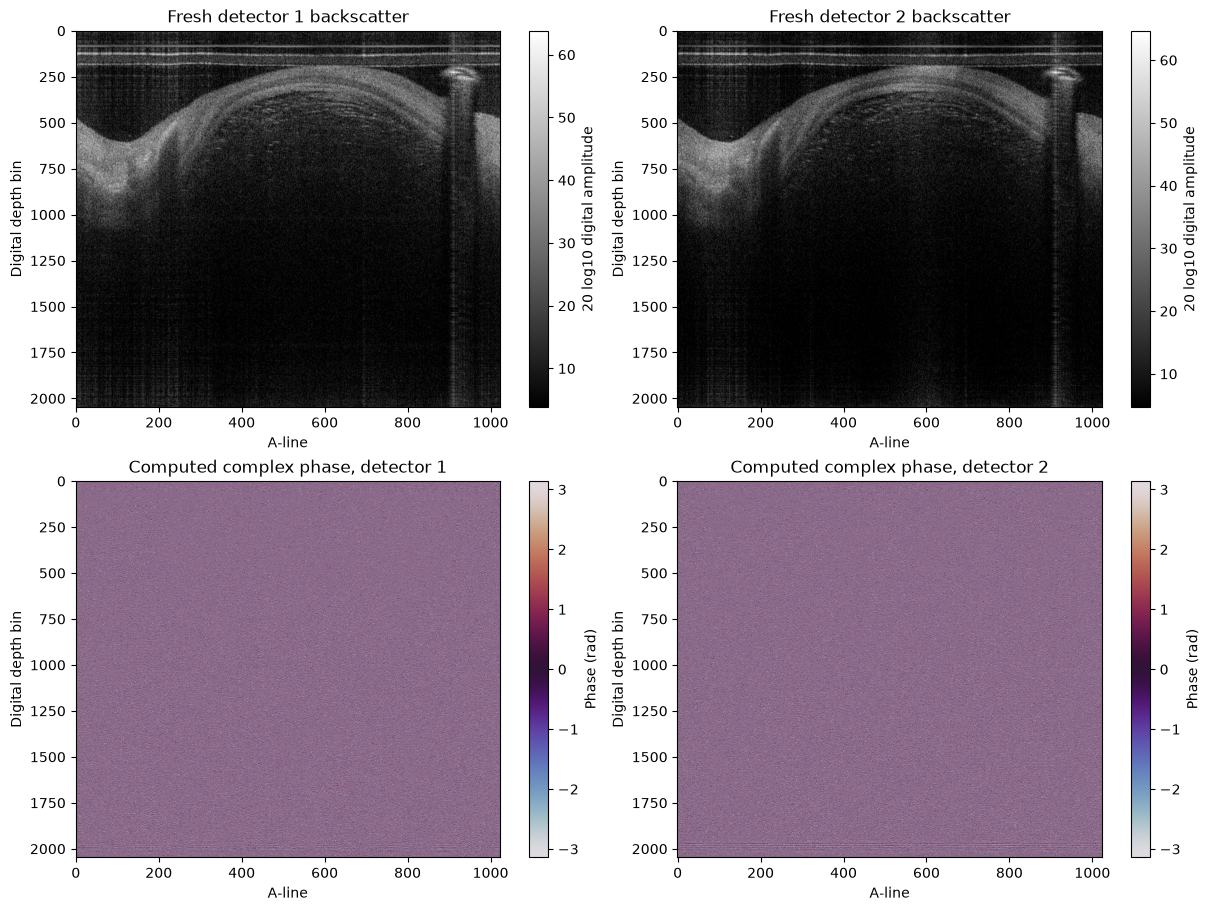

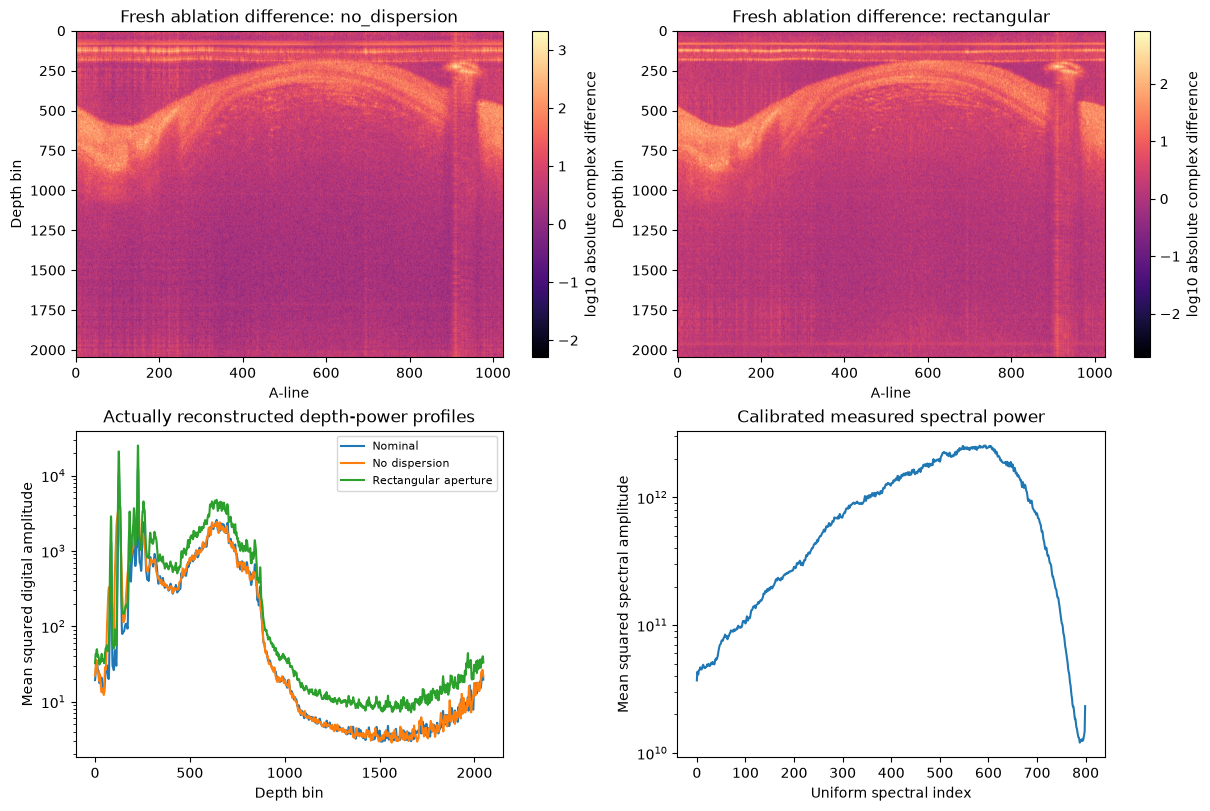

In [2]:
figures=make_figures(data,experiments)
for fig in figures:
    display(fig)
    plt.close(fig)

The following separately identified cleaned-run measurements are frozen scalar results from this task’s fresh local experiment run. The active reconstruction above remains the source of every plotted result; this archive records numeric provenance rather than supplying a reconstruction.


In [3]:
with np.load(root / 'notebooks/reference_outputs/cleaned_metrics.npz', allow_pickle=False) as recorded:
    print('Separately archived fresh cleaned-run measurements:', {k: recorded[k].tolist() for k in recorded.files})


Separately archived fresh cleaned-run measurements: {'nominal_upstream_relative_l2': 0.0, 'no_dispersion_change': 1.6091532328970248, 'rectangular_window_change': 0.5833476914477054}


## 6. Conclusion

### Numerical validation and conclusion
The independently captured original result and fresh local result agree under the fixed complex-array metric. A separate analytic tone fixes depth orientation, DFT sign and Parseval scale. Reverse transformation checks that the resulting depth image reproduces the calibrated Hann-windowed observed spectral representation. The demonstrated differences between ablations are computed, not historical paper measurements. Physical pixel/depth lengths and absolute reflectivity are not deposited, so all plots explicitly retain digital indices and amplitude units.

This benchmark reconstructs an unknown spatial tissue backscatter image from raw indirect interferometric measurements. The standard-method reference validates implementation reproducibility; it does not certify tissue histology.

The no-dispersion and rectangular-window runs test calibration and aperture sensitivity. Complex parity and the inverse spectral check fix digital scale and depth orientation. Missing physical pixel/depth calibration prevents assigning absolute tissue thickness or reflectivity.
